## Predicting Osteoporosis Risk

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# Statistical analysis
from scipy.stats import chi2_contingency

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [ ]:
df = pd.read_csv("osteoporosis.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (1958, 16)


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,104866,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,101999,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,106567,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,102316,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,101944,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1


In [ ]:
# Basic data understanding

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

Rows: 1958
Columns: 16

Column names:
['Id', 'Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']

Data types:


,dtype
Id,int64
Age,int64
Gender,object
Hormonal Changes,object
Family History,object
Race/Ethnicity,object
Body Weight,object
Calcium Intake,object
Vitamin D Intake,object
Physical Activity,object



First 5 rows:


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,104866,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,101999,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,106567,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,102316,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,101944,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1



Last 5 rows:


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
1953,106130,19,Female,Normal,Yes,African American,Normal,Adequate,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,NaN,Yes,0
1954,106463,23,Female,Postmenopausal,Yes,Caucasian,Underweight,Low,Insufficient,Active,No,NaN,NaN,Corticosteroids,No,0
1955,103142,34,Female,Postmenopausal,No,African American,Underweight,Low,Sufficient,Sedentary,No,NaN,Hyperthyroidism,NaN,No,0
1956,105187,25,Male,Postmenopausal,No,African American,Normal,Low,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,Yes,0
1957,108561,26,Female,Postmenopausal,No,African American,Underweight,Adequate,Sufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   1958 non-null   int64 
 1   Age                  1958 non-null   int64 
 2   Gender               1958 non-null   object
 3   Hormonal Changes     1958 non-null   object
 4   Family History       1958 non-null   object
 5   Race/Ethnicity       1958 non-null   object
 6   Body Weight          1958 non-null   object
 7   Calcium Intake       1958 non-null   object
 8   Vitamin D Intake     1958 non-null   object
 9   Physical Activity    1958 non-null   object
 10  Smoking              1958 non-null   object
 11  Alcohol Consumption  970 non-null    object
 12  Medical Conditions   1311 non-null   object
 13  Medications          973 non-null    object
 14  Prior Fractures      1958 non-null   object
 15  Osteoporosis         1958 non-null   int64 
dtypes: int

In [ ]:
df.describe()

,Id,Age,Osteoporosis
count,1958.000000,1958.000000,1958.000000
mean,105515.320735,39.101124,0.500000
std,2589.407806,21.355424,0.500128
min,101008.000000,18.000000,0.000000
25%,103348.500000,21.000000,0.000000
50%,105469.000000,32.000000,0.500000
75%,107755.000000,53.000000,1.000000
max,109996.000000,90.000000,1.000000


In [ ]:
df.describe(include="all")

,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
count,1958.000000,1958.000000,1958,1958,1958,1958,1958,1958,1958,1958,1958,970,1311,973,1958,1958.000000
unique,NaN,NaN,2,2,2,3,2,2,2,2,2,1,2,1,2,NaN
top,NaN,NaN,Male,Normal,No,African American,Normal,Low,Sufficient,Active,Yes,Moderate,Hyperthyroidism,Corticosteroids,Yes,NaN
freq,NaN,NaN,992,981,998,681,1027,1004,1011,1021,982,970,678,973,983,NaN
mean,105515.320735,39.101124,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.500000
std,2589.407806,21.355424,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.500128
min,101008.000000,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,103348.500000,21.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,105469.000000,32.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.500000
75%,107755.000000,53.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000


In [ ]:
for column in df.columns:
    print(f"\n{column}")
    print(df[column].unique())


Id
[104866 101999 106567 ... 106130 105187 108561]

Age
[69 32 89 78 38 41 20 39 70 19 47 55 81 77 50 75 66 76 59 79 64 68 72 24
 90 56 35 21 31 26 88 61 25 52 53 67 23 71 80 51 65 57 43 58 46 62 82 18
 28 22 45 29 40 54 44 60 30 49 83 74 87 73 36 85 34 86 33 37 84 48 42 63
 27]

Gender
['Female' 'Male']

Hormonal Changes
['Normal' 'Postmenopausal']

Family History
['Yes' 'No']

Race/Ethnicity
['Asian' 'Caucasian' 'African American']

Body Weight
['Underweight' 'Normal']

Calcium Intake
['Low' 'Adequate']

Vitamin D Intake
['Sufficient' 'Insufficient']

Physical Activity
['Sedentary' 'Active']

Smoking
['Yes' 'No']

Alcohol Consumption
['Moderate' nan]

Medical Conditions
['Rheumatoid Arthritis' nan 'Hyperthyroidism']

Medications
['Corticosteroids' nan]

Prior Fractures
['Yes' 'No']

Osteoporosis
[1 0]


In [ ]:
df.isnull().sum()

Id                       0
Age                      0
Gender                   0
Hormonal Changes         0
Family History           0
Race/Ethnicity           0
Body Weight              0
Calcium Intake           0
Vitamin D Intake         0
Physical Activity        0
Smoking                  0
Alcohol Consumption    988
Medical Conditions     647
Medications            985
Prior Fractures          0
Osteoporosis             0
dtype: int64

In [ ]:
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

missing_percentage

Id                      0.00
Age                     0.00
Gender                  0.00
Hormonal Changes        0.00
Family History          0.00
Race/Ethnicity          0.00
Body Weight             0.00
Calcium Intake          0.00
Vitamin D Intake        0.00
Physical Activity       0.00
Smoking                 0.00
Alcohol Consumption    50.46
Medical Conditions     33.04
Medications            50.31
Prior Fractures         0.00
Osteoporosis            0.00
dtype: float64

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_summary

,Missing Count,Missing Percentage
Id,0,0.00
Age,0,0.00
Gender,0,0.00
Hormonal Changes,0,0.00
Family History,0,0.00
Race/Ethnicity,0,0.00
Body Weight,0,0.00
Calcium Intake,0,0.00
Vitamin D Intake,0,0.00
Physical Activity,0,0.00


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated(keep=False)]

,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis


In [ ]:
# check for duplicate IDs
df["Id"].duplicated().sum()

np.int64(209)

In [ ]:
# check for duplicate IDs and display the rows with duplicate IDs
duplicate_ids = df[
    df["Id"].duplicated(keep=False)
].sort_values("Id")

duplicate_ids.head(20)

,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
77,101027,82,Female,Normal,No,Asian,Underweight,Low,Insufficient,Active,No,Moderate,NaN,Corticosteroids,No,1
1497,101027,29,Female,Postmenopausal,Yes,Caucasian,Normal,Low,Insufficient,Active,No,Moderate,NaN,Corticosteroids,No,0
1544,101148,25,Female,Postmenopausal,No,African American,Underweight,Low,Insufficient,Active,No,Moderate,Hyperthyroidism,NaN,No,0
736,101148,21,Male,Normal,Yes,Asian,Normal,Adequate,Insufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,No,1
720,101162,59,Female,Postmenopausal,Yes,African American,Underweight,Low,Sufficient,Active,Yes,Moderate,Hyperthyroidism,NaN,Yes,1
650,101162,25,Male,Normal,No,Caucasian,Underweight,Adequate,Sufficient,Active,Yes,NaN,Hyperthyroidism,Corticosteroids,Yes,1
647,101170,40,Male,Postmenopausal,No,Asian,Normal,Adequate,Sufficient,Active,No,NaN,Hyperthyroidism,Corticosteroids,No,1
1297,101170,35,Male,Normal,No,Caucasian,Normal,Adequate,Insufficient,Active,Yes,NaN,NaN,NaN,Yes,0
1385,101180,20,Male,Postmenopausal,Yes,Asian,Normal,Adequate,Sufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,0
1941,101180,20,Male,Postmenopausal,No,African American,Normal,Adequate,Sufficient,Active,Yes,Moderate,NaN,NaN,Yes,0


In [ ]:
# check the distribution of the target variable
df["Osteoporosis"].value_counts()


Osteoporosis
1    979
0    979
Name: count, dtype: int64

In [ ]:
# check the distribution of the target variable in percentage
df["Osteoporosis"].value_counts(normalize=True) * 100

Osteoporosis
1    50.0
0    50.0
Name: proportion, dtype: float64

In [ ]:
# check for inconsistencie harmonal changes 
pd.crosstab(
    df["Gender"],
    df["Hormonal Changes"]
)

Hormonal Changes,Normal,Postmenopausal
Gender,,
Female,475,491
Male,506,486


In [ ]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


Gender
Gender
Male      992
Female    966
Name: count, dtype: int64

Hormonal Changes
Hormonal Changes
Normal            981
Postmenopausal    977
Name: count, dtype: int64

Family History
Family History
No     998
Yes    960
Name: count, dtype: int64

Race/Ethnicity
Race/Ethnicity
African American    681
Caucasian           646
Asian               631
Name: count, dtype: int64

Body Weight
Body Weight
Normal         1027
Underweight     931
Name: count, dtype: int64

Calcium Intake
Calcium Intake
Low         1004
Adequate     954
Name: count, dtype: int64

Vitamin D Intake
Vitamin D Intake
Sufficient      1011
Insufficient     947
Name: count, dtype: int64

Physical Activity
Physical Activity
Active       1021
Sedentary     937
Name: count, dtype: int64

Smoking
Smoking
Yes    982
No     976
Name: count, dtype: int64

Alcohol Consumption
Alcohol Consumption
NaN         988
Moderate    970
Name: count, dtype: int64

Medical Conditions
Medical Conditions
Hyperthyroidism         678
NaN

In [ ]:
for column in ["Alcohol Consumption", "Medical Conditions", "Medications"]:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


Alcohol Consumption:
Alcohol Consumption
NaN         988
Moderate    970
Name: count, dtype: int64

Medical Conditions:
Medical Conditions
Hyperthyroidism         678
NaN                     647
Rheumatoid Arthritis    633
Name: count, dtype: int64

Medications:
Medications
NaN                985
Corticosteroids    973
Name: count, dtype: int64


## Exploratory Data Analysis (EDA)

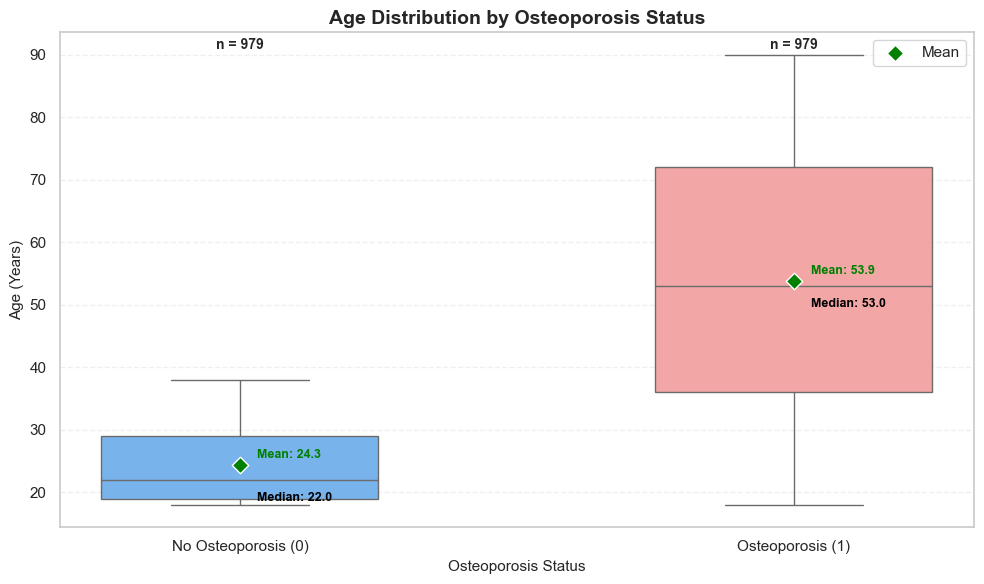

In [ ]:
# age distribution by osteoporosis status

plt.figure(figsize=(10, 6))

# Boxplot
ax = sns.boxplot(
    data=df,
    x="Osteoporosis",
    y="Age",
    hue="Osteoporosis",
    palette={0: "#66B3FF", 1: "#FF9999"},
    width=0.5,
    showfliers=False,
    legend=False
)

# Add mean, median and sample count
for i, status in enumerate(sorted(df["Osteoporosis"].dropna().unique())):

    group = df[df["Osteoporosis"] == status]["Age"]

    mean_age = group.mean()
    median_age = group.median()
    count = group.count()

    # Mean marker
    ax.scatter(
        i,
        mean_age,
        color="green",
        marker="D",
        s=70,
        edgecolor="white",
        zorder=5,
        label="Mean" if i == 0 else ""
    )

    # Mean label
    ax.annotate(
        f"Mean: {mean_age:.1f}",
        (i, mean_age),
        xytext=(12, 5),
        textcoords="offset points",
        fontsize=9,
        color="green",
        fontweight="bold"
    )

    # Median label
    ax.annotate(
        f"Median: {median_age:.1f}",
        (i, median_age),
        xytext=(12, -15),
        textcoords="offset points",
        fontsize=9,
        color="black",
        fontweight="bold"
    )

    # Sample count
    ax.text(
        i,
        df["Age"].max() + 1,
        f"n = {count}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Age Distribution by Osteoporosis Status",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Osteoporosis Status", fontsize=11)
plt.ylabel("Age (Years)", fontsize=11)

plt.xticks(
    [0, 1],
    ["No Osteoporosis (0)", "Osteoporosis (1)"]
)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


Osteoporosis,0,1
Gender,,
Female,489,477
Male,490,502


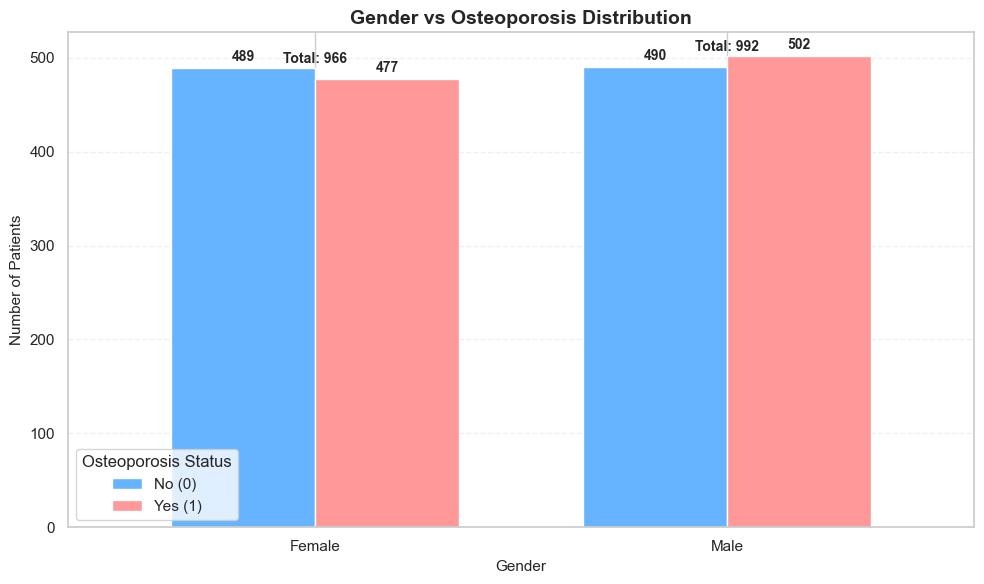

In [ ]:
# gender distribution by osteoporosis status

# Gender vs Osteoporosis
gender_counts = pd.crosstab(df["Gender"], df["Osteoporosis"])

display(gender_counts)

# Create grouped bar chart
ax = gender_counts.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#66B3FF", "#FF9999"],
    width=0.7
)

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3,
        fontsize=10,
        fontweight="bold"
    )

# Add total sample count above each gender group
for i, gender in enumerate(gender_counts.index):
    total = gender_counts.loc[gender].sum()

    ax.text(
        i,
        gender_counts.loc[gender].max() + 5,
        f"Total: {total}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Gender vs Osteoporosis Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Gender", fontsize=11)
plt.ylabel("Number of Patients", fontsize=11)

plt.xticks(rotation=0)
plt.legend(
    title="Osteoporosis Status",
    labels=["No (0)", "Yes (1)"]
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Calculate gender percentages by osteoporosis status

gender_percentages = pd.crosstab(
    df["Gender"], df["Osteoporosis"], normalize="index"
) * 100
display(gender_percentages.round(2))

Osteoporosis,0,1
Gender,,
Female,50.62,49.38
Male,49.40,50.60


Osteoporosis,0,1
Family History,,
No,498,500
Yes,481,479


Osteoporosis,0,1
Family History,,
No,49.9,50.1
Yes,50.1,49.9


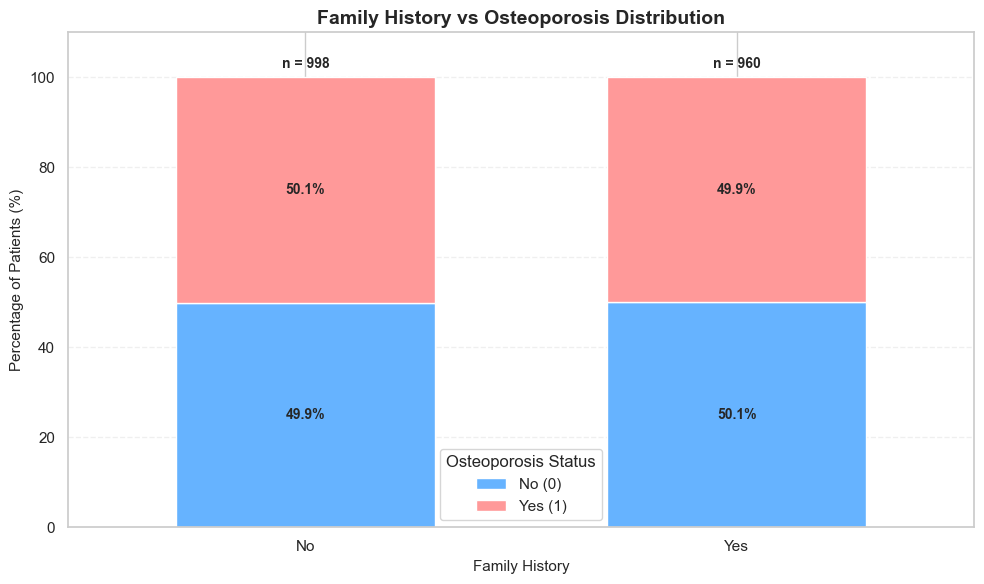

In [ ]:
# check for family history vs osteoporosis status

# Family History vs Osteoporosis
family_history_counts = pd.crosstab(
    df["Family History"],
    df["Osteoporosis"]
)

# Calculate percentages
family_history_percentages = pd.crosstab(
    df["Family History"],
    df["Osteoporosis"],
    normalize="index"
) * 100

display(family_history_counts)
display(family_history_percentages.round(2))

# Plot
ax = family_history_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#66B3FF", "#FF9999"],
    width=0.6
)

# Add percentage labels inside bars
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%" if bar.get_height() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=10,
        fontweight="bold"
    )

# Add sample counts above bars
for i, history in enumerate(family_history_counts.index):
    total = family_history_counts.loc[history].sum()

    ax.text(
        i,
        102,
        f"n = {total}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Family History vs Osteoporosis Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Family History", fontsize=11)
plt.ylabel("Percentage of Patients (%)", fontsize=11)

plt.xticks(rotation=0)
plt.ylim(0, 110)

plt.legend(
    title="Osteoporosis Status",
    labels=["No (0)", "Yes (1)"]
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


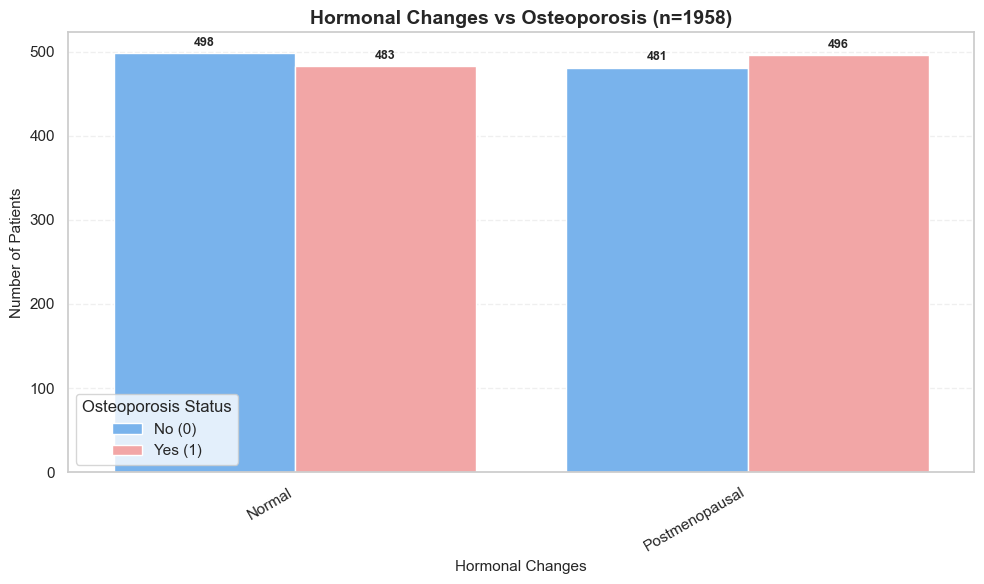

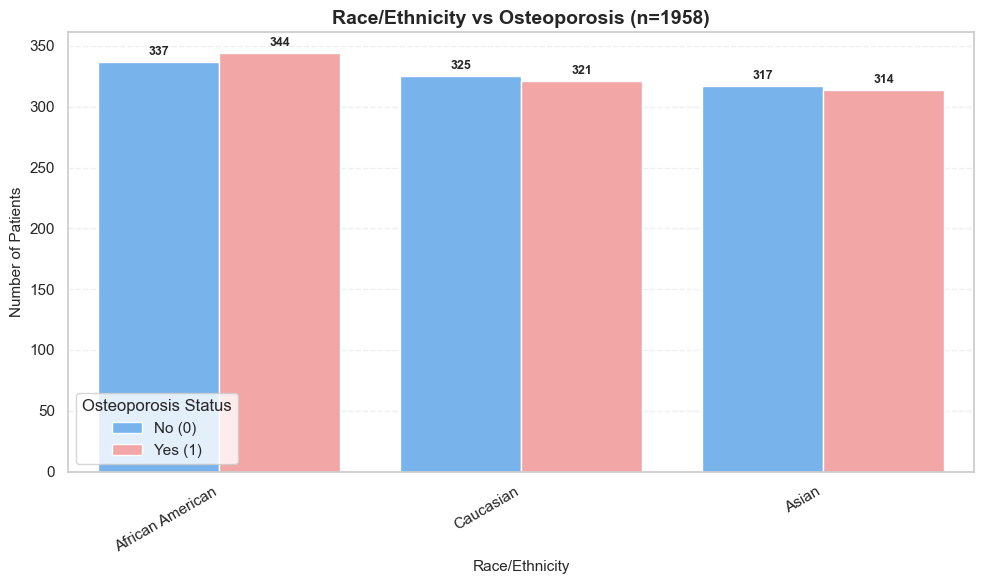

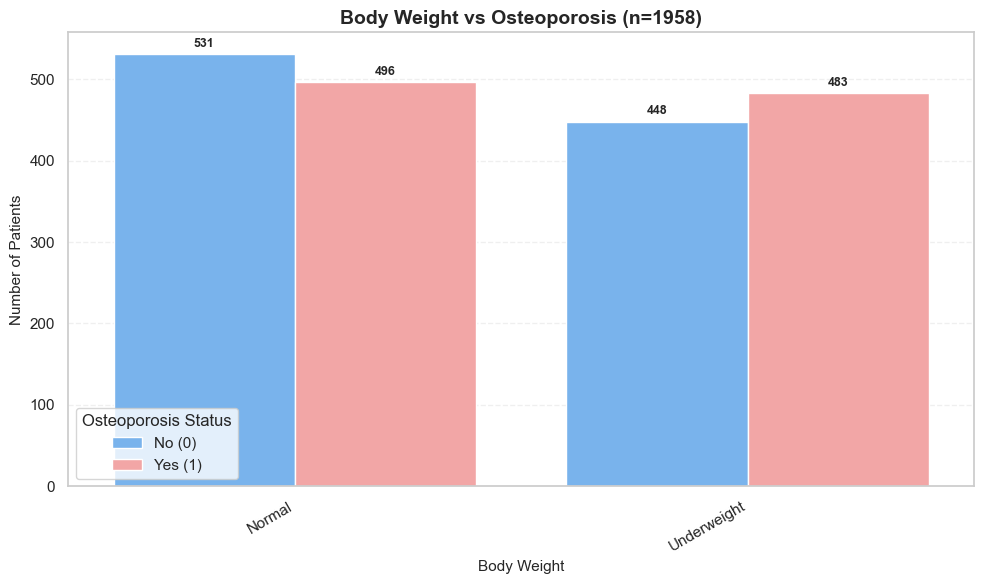

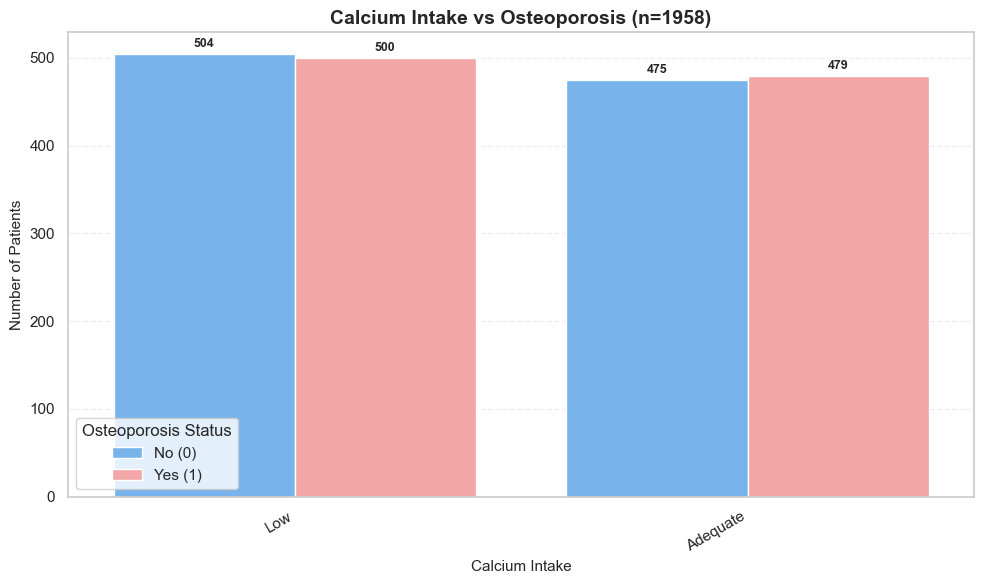

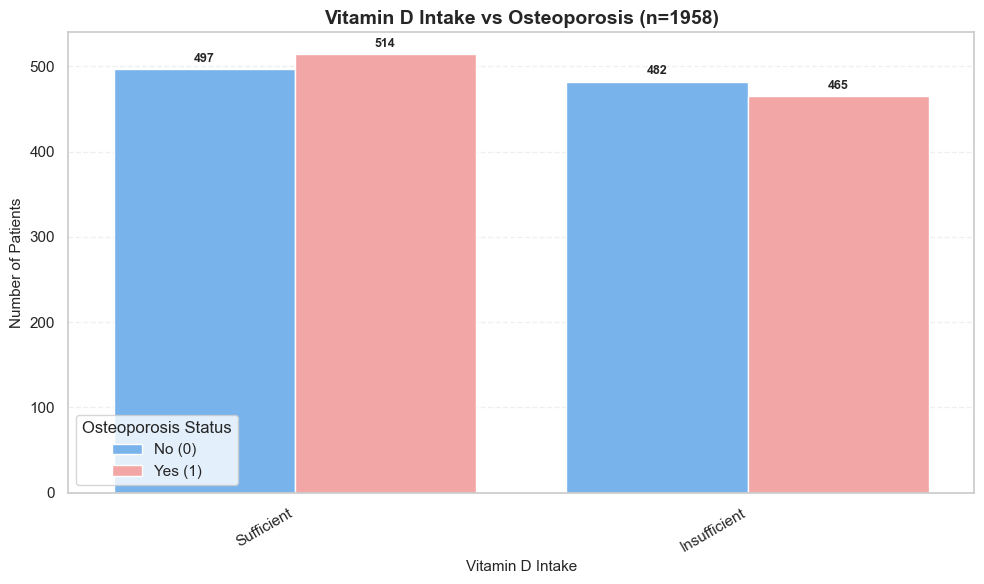

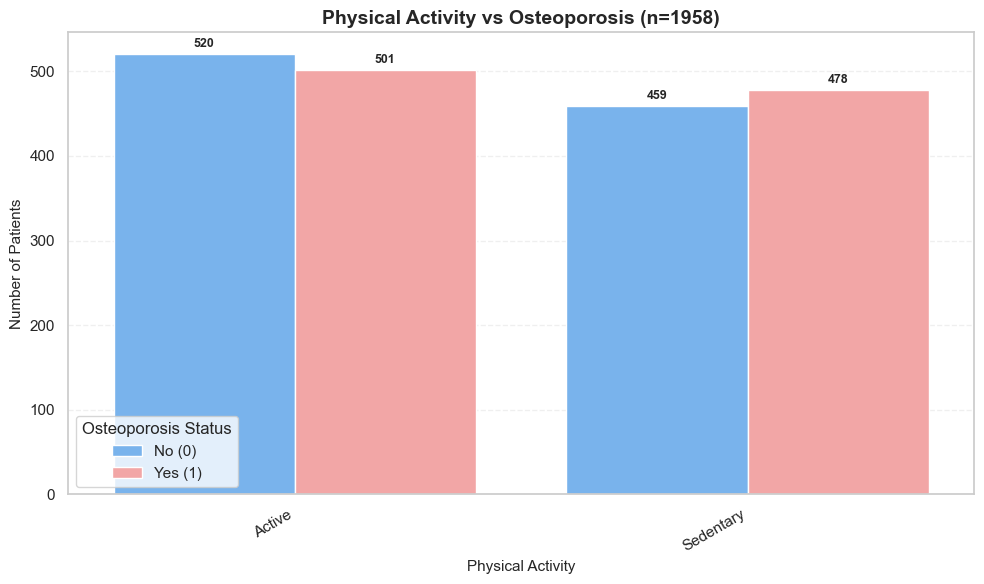

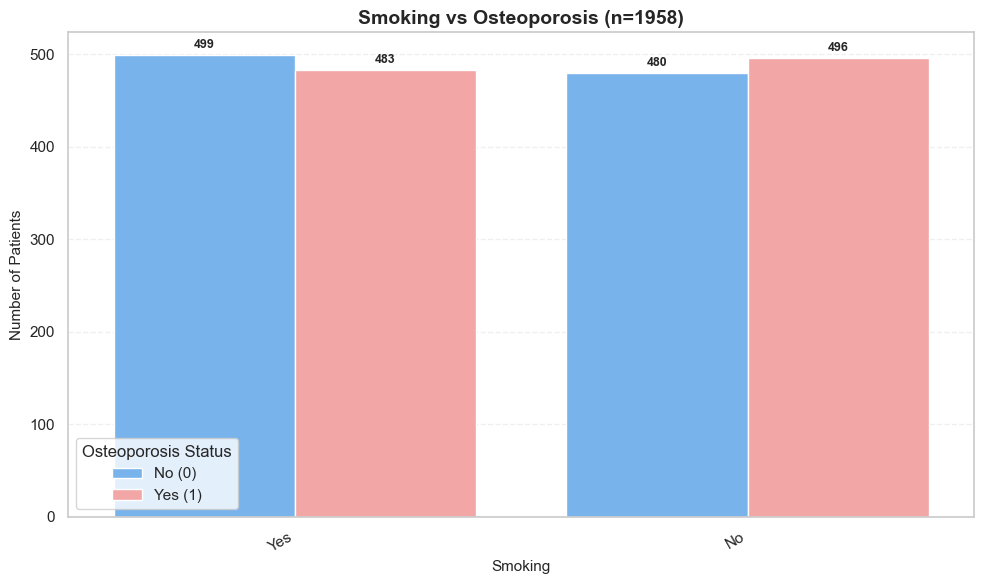

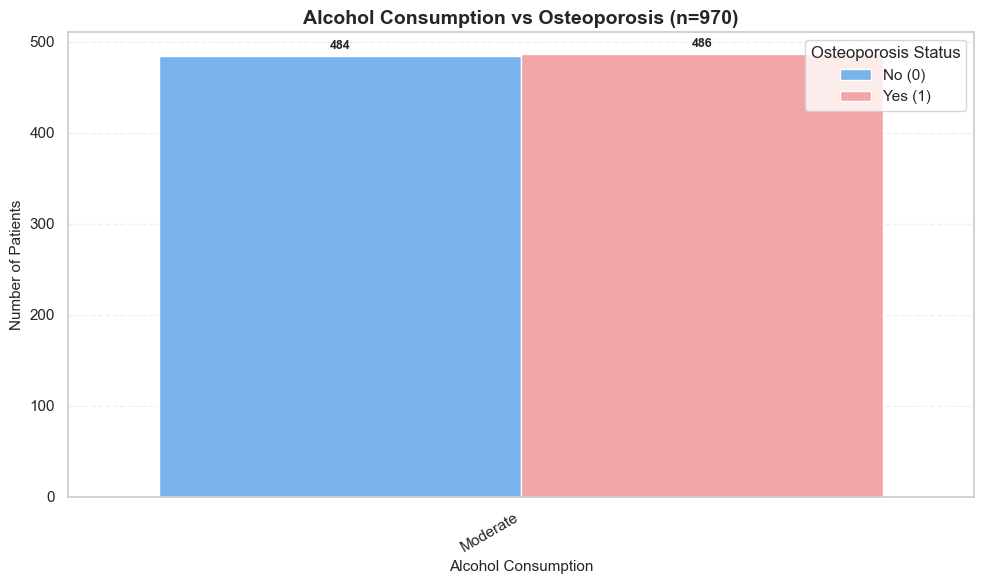

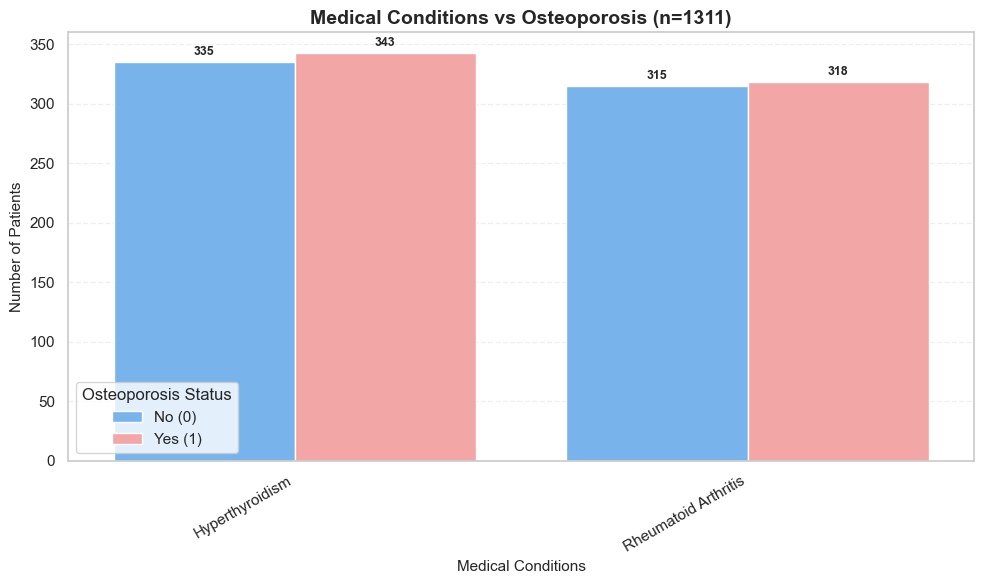

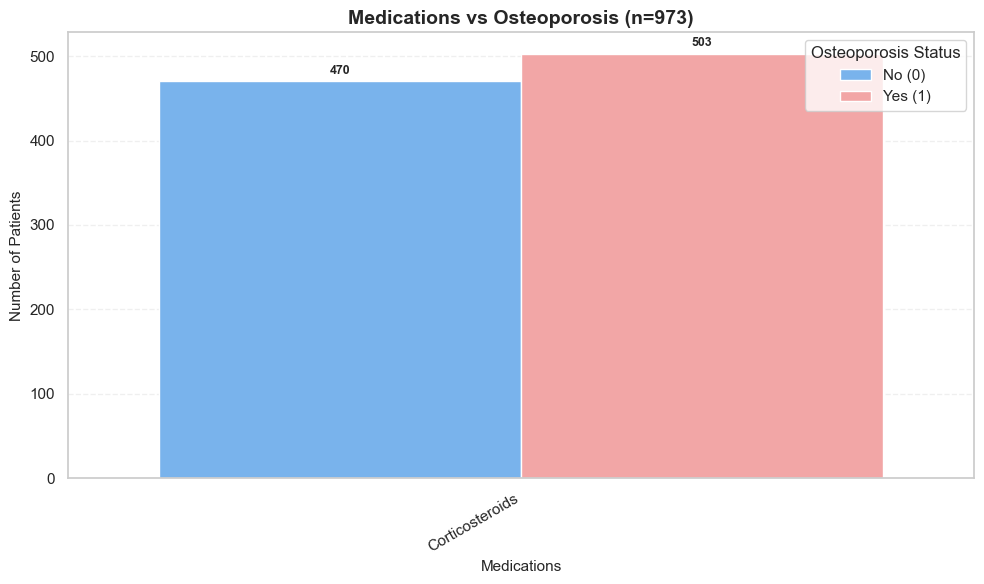

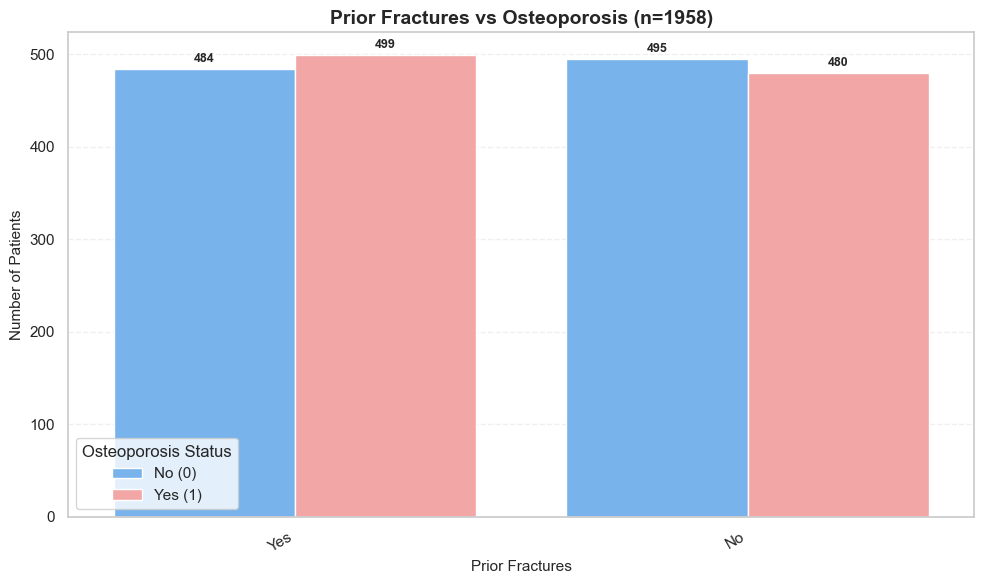

In [ ]:
# Compare other features with osteoporosis status

features_to_compare = [
    "Hormonal Changes",
    "Race/Ethnicity",
    "Body Weight",
    "Calcium Intake",
    "Vitamin D Intake",
    "Physical Activity",
    "Smoking",
    "Alcohol Consumption",
    "Medical Conditions",
    "Medications",
    "Prior Fractures"
]

for feature in features_to_compare:

    plt.figure(figsize=(10, 6))

    # Count plot
    ax = sns.countplot(
        data=df,
        x=feature,
        hue="Osteoporosis",
        palette={
            0: "#66B3FF",
            1: "#FF9999"
        },
        order=df[feature].value_counts().index
    )

    # Add count labels
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="%d",
            padding=3,
            fontsize=9,
            fontweight="bold"
        )

    # Total sample size
    total = df[feature].notna().sum()

    plt.title(
        f"{feature} vs Osteoporosis (n={total})",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel(feature, fontsize=11)
    plt.ylabel("Number of Patients", fontsize=11)

    plt.xticks(rotation=30, ha="right")

    plt.legend(
        title="Osteoporosis Status",
        labels=["No (0)", "Yes (1)"]
    )

    plt.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


In [ ]:
# Display percentage tables for each feature vs osteoporosis status
for feature in features_to_compare:
    print(f"\n--- {feature} vs Osteoporosis (%) ---")
    percentage_table = pd.crosstab(
        df[feature], df["Osteoporosis"], normalize="index"
    ) * 100
    display(percentage_table.round(2))


--- Hormonal Changes vs Osteoporosis (%) ---


Osteoporosis,0,1
Hormonal Changes,,
Normal,50.76,49.24
Postmenopausal,49.23,50.77



--- Race/Ethnicity vs Osteoporosis (%) ---


Osteoporosis,0,1
Race/Ethnicity,,
African American,49.49,50.51
Asian,50.24,49.76
Caucasian,50.31,49.69



--- Body Weight vs Osteoporosis (%) ---


Osteoporosis,0,1
Body Weight,,
Normal,51.70,48.30
Underweight,48.12,51.88


... (12 outputs left out)


--- Medications vs Osteoporosis (%) ---


Osteoporosis,0,1
Medications,,
Corticosteroids,48.3,51.7



--- Prior Fractures vs Osteoporosis (%) ---


Osteoporosis,0,1
Prior Fractures,,
No,50.77,49.23
Yes,49.24,50.76


# Chi-square tests for categorical associations

- H₀: The feature and target are independent.
- H₁: The feature and target are associated.

A p-value below 0.05 is commonly treated as evidence against independence. It does not prove causation or measure association strength. Inspect expected cell counts and consider effect size and multiple-comparison issues when interpreting results.

In [ ]:
# Perform Chi-square tests for each feature vs osteoporosis status

chi_square_results = []

for feature in features_to_compare:
    contingency_table = pd.crosstab(df[feature], df["Osteoporosis"])
    chi2, p_value, degrees_of_freedom, expected = chi2_contingency(contingency_table)

    chi_square_results.append({
        "Feature": feature,
        "Chi-square statistic": chi2,
        "Degrees of freedom": degrees_of_freedom,
        "P-value": p_value,
        "Significant at 0.05": p_value < 0.05
    })

chi_square_summary = pd.DataFrame(chi_square_results).sort_values("P-value")
display(chi_square_summary)

,Feature,Chi-square statistic,Degrees of freedom,P-value,Significant at 0.05
2,Body Weight,2.367284,1,0.123902,False
5,Physical Activity,0.663120,1,0.415460,False
4,Vitamin D Intake,0.523542,1,0.469335,False
6,Smoking,0.459657,1,0.497784,False
10,Prior Fractures,0.400415,1,0.526875,False
0,Hormonal Changes,0.400410,1,0.526877,False
3,Calcium Intake,0.018398,1,0.892106,False
8,Medical Conditions,0.005252,1,0.942226,False
1,Race/Ethnicity,0.110984,2,0.946020,False
7,Alcohol Consumption,0.000000,0,1.000000,False


# Separate features and target

In [ ]:
df["Age"] = pd.to_numeric(df["Age"], errors="raise")
df["Osteoporosis"] = pd.to_numeric(df["Osteoporosis"], errors="raise")

print("Target values:", sorted(df["Osteoporosis"].unique()))
print("Target missing values:", df["Osteoporosis"].isna().sum())

X = df.drop(columns=["Id", "Osteoporosis"])
y = df["Osteoporosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

Target values: [np.int64(0), np.int64(1)]
Target missing values: 0
X shape: (1958, 14)
y shape: (1958,)


# Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1566, 14)
Testing features: (392, 14)
Training target: (1566,)
Testing target: (392,)


In [ ]:
# Display target counts and percentages for training and testing sets

print("Training target counts:")
display(y_train.value_counts().sort_index())

print("Testing target counts:")
display(y_test.value_counts().sort_index())

print("Training target percentages:")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("Testing target percentages:")
display((y_test.value_counts(normalize=True).sort_index() * 100).round(2))

Training target counts:


Osteoporosis
0    783
1    783
Name: count, dtype: int64

Testing target counts:


Osteoporosis
0    196
1    196
Name: count, dtype: int64

Training target percentages:


Osteoporosis
0    50.0
1    50.0
Name: proportion, dtype: float64

Testing target percentages:


Osteoporosis
0    50.0
1    50.0
Name: proportion, dtype: float64

In [ ]:
# Identify numerical and categorical features
numerical_features = ["Age"]

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features: ['Age']
Categorical features: ['Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures']
Number of numerical features: 1
Number of categorical features: 13


# Numerical preprocessing pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [ ]:
from sklearn.pipeline import Pipeline
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

NameError: name 'Pipeline' is not defined